**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**10 | Raw-IMU Temporal Classification with PyTorch**

![Stage 10 scientific workflow](../../images/10_workflow.svg)

**Objective:** Train a compact 1D-CNN on six-channel HARTH acceleration windows and evaluate its bounded, participant-disjoint Development performance.

**Dataset:** The pinned HARTH v2.0 Development cohort, with up to 500 label-pure, two-second windows sampled per participant.

**Notebook Scope:** Fit channel scaling on Train only, train the temporal CNN for five epochs and inspect Validation Macro F1 and class-specific errors. Reserved Test recordings S023 and S032 are not loaded. Sampling and evaluation differ from the full-cohort classical ML comparison, so direct model rankings across these protocols are not justified.

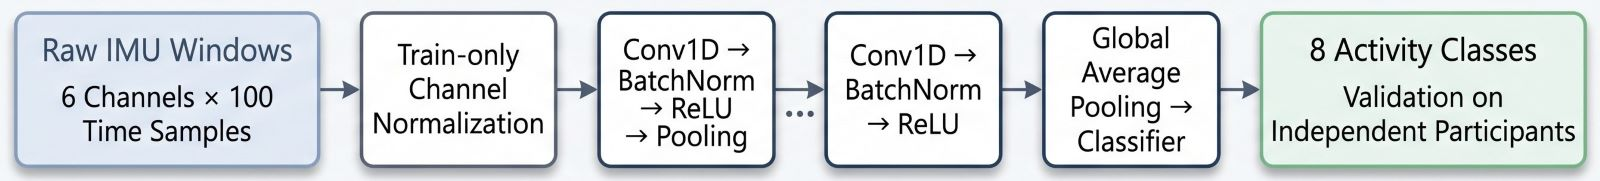

**00. Colab Repository Setup**

**01. Imports and Research Environment**

In [ ]:
# ======================== 00. Colab Repository Setup =========================

# ------------------------- Repository Configuration --------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

# ------------------------ Clone Repository if Missing ------------------------
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ------------------------------ Open Repository ------------------------------
%cd {repo_path}


In [ ]:
# =================== 01. Imports and Research Environment ====================

# ---------------------- Study Environment Configuration ----------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------- Standard Library and Scientific Computing -----------------
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch

# ---------------------- Data Visualisation and Display -----------------------
import matplotlib.pyplot as plt
from IPython.display import display

# ---------------------- HARTH Cohort and CNN Utilities -----------------------
from harth_data import (
    HARTH_SUBJECTS,
    ACTIVITY_NAMES,
    prepare_harth_window_cohort,
)
from core.data_splitting import split_group_indices
from core.temporal_cnn import TemporalCNN, train_temporal_cnn

# -------------------------------- Plot Style ---------------------------------
from core.plot_style import plot_style
plot_style()

# ------------------------- Training Device Selection -------------------------
from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type

print("Repository root:", root)
print("Training compute device:", DEVICE)


**02. Define the Bounded Raw-Signal Experiment**

Use all 29 Development participants with a deterministic cap of 500 eligible windows per person, sampled without using labels. The saved cohort contains 14,201 windows; this computational cap can change activity representation and does not balance the classes.

In [ ]:
# ================== 02. Construct Bounded Raw-Window Cohort ==================

# ------------------- Reserved Test and Development Cohorts -------------------
RESERVED_TEST = {"S023", "S032"}

DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)

# ------------------------ Documented Activity Classes ------------------------
TASK_CLASSES = tuple(range(1, 9))

# ----------------------- Subject-Level Sampling Limit ------------------------
MAX_WINDOWS_PER_SUBJECT = 500

# ----------------------------- Cohort Integrity ------------------------------
assert len(DEVELOPMENT_SUBJECTS) == 29
assert not (set(DEVELOPMENT_SUBJECTS) & RESERVED_TEST)

# ------------------------ Bounded Raw Signal Windows -------------------------
X, y, metadata, overview = prepare_harth_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES,
    max_windows_per_subject=MAX_WINDOWS_PER_SUBJECT,  # Limit sampling within each Development participant.
    window_size=100, step_size=50, sampling_rate=50,
)

# ------------------------- Cohort and Tensor Summary -------------------------
display(overview)

print("Real raw IMU tensor:", X.shape)
print("Label vector:", y.shape)
print("Subjects:", metadata["subject_id"].nunique())


**03. Create Subject-Disjoint Train and Validation Groups**

Split whole participants rather than overlapping windows. The `unused_development` partition contains three Development participants and is distinct from reserved final Test identities S023 and S032.

In [ ]:
# ================ 03. Separate Train and Validation Subjects =================

# ---------------------- Participant-Disjoint Splitting -----------------------
parts = split_group_indices(
    metadata["subject_id"].to_numpy(),
    train_fraction=0.70, validation_fraction=0.20,
    test_fraction=0.10, random_state=42,  # Unused Development subset, not the reserved Test cohort.
)

# ----------------------- Participant Group Membership ------------------------
group_names = {
    name: sorted(metadata.iloc[idx]["subject_id"].unique().tolist())
    for name, idx in parts.items()
}

# ---------------------- Train and Validation Separation ----------------------
assert not (set(group_names["train"]) & set(group_names["validation"]))
assert not (set(group_names["train"]) & set(group_names["test"]))
assert not (set(group_names["validation"]) & set(group_names["test"]))

# ----------------------- Training and Validation Data ------------------------
train_rows = parts["train"]
validation_rows = parts["validation"]

X_train, y_train = X[train_rows], y[train_rows]
X_validation, y_validation = X[validation_rows], y[validation_rows]

# ----------------------------- Partition Summary -----------------------------
display(pd.DataFrame([
    {"role": "Train", "subjects": len(group_names["train"]),
     "windows": len(train_rows), "subject_ids": ", ".join(group_names["train"])},
    {"role": "Validation", "subjects": len(group_names["validation"]),
     "windows": len(validation_rows), "subject_ids": ", ".join(group_names["validation"])},
    {"role": "Unused development", "subjects": len(group_names["test"]),
     "windows": len(parts["test"]), "subject_ids": ", ".join(group_names["test"])},
]))

print("Original reserved final Test loaded: NO")


**04. Audit Source Classes and Temporal Model Input**

Check that Train contains all eight target classes and that the CNN input follows `(batch, channels, time)`, rather than the previously engineered 30-feature representation.

In [ ]:
# ==================== 04. Audit Classes and Raw CNN Input ====================

# -------------------- Train and Validation Class Coverage --------------------
counts = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(),
    "validation": pd.Series(y_validation).value_counts(),
}).reindex(TASK_CLASSES, fill_value=0).fillna(0).astype(int)

counts.index = [f"{code}: {ACTIVITY_NAMES[code]}" for code in TASK_CLASSES]

display(counts)

# ------------------ CNN Architecture and Forward-Pass Check ------------------
assert (counts["train"] > 0).all(), "Training class coverage is incomplete."

model_preview = TemporalCNN(in_channels=6, n_classes=8)

example_output = model_preview(torch.from_numpy(X_train[:4]))

print("Example CNN output shape:", tuple(example_output.shape))
print("Untrained classifier output is logits, not probabilities.")


**05. Train the Compact 1D-CNN with Train-Only Scaling**

Estimate channel means and standard deviations from Train windows only. Train the CNN for five epochs using raw signal sequences; CPU is the default device, with CUDA used when available. This is a bounded feasibility experiment, not a hyperparameter-matched benchmark against classical models.

In [ ]:
# =================== 05. Train the Compact PyTorch 1D-CNN ====================

# ------------------------ Training Budget and Device -------------------------
EPOCHS = 5

BATCH_SIZE = 128
LEARNING_RATE = 1e-3
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Training device:", DEVICE)

# -------------------------- Train-Only CNN Fitting ---------------------------
model, history, validation_pred, scaling = train_temporal_cnn(
    X_train=X_train, y_train=y_train,
    X_validation=X_validation, y_validation=y_validation,
    classes=TASK_CLASSES,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE, seed=42, device=DEVICE,  # Fit channel normalisation on Train data only.
)

# ------------------- Training History and Channel Scaling --------------------
display(history.round(4))

print("Channel means fitted from Train:", np.round(scaling["channel_mean"], 4))


**06. Visualise Learning Curves and Validation Scores**

Plot training loss and Validation Macro F1 in separate panels. Report the final epoch without selecting a model using reserved Test data.

In [ ]:
# =============== 06. Visualise Training and Validation Trends ================

# ---------------------------- Training Loss Curve ----------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["epoch"], history["train_loss"], marker="o")
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].grid(alpha=0.25)

# ------------------------- Validation Macro F1 Curve -------------------------
axes[1].plot(history["epoch"], history["validation_macro_f1"], marker="o")
axes[1].set(title="Validation Macro F1", xlabel="Epoch",
            ylabel="Macro F1", ylim=(0, 1))
axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()


**07. Inspect Last-Epoch Activity Classification Errors**

Examine the eight-class confusion matrix and class-specific scores for the bounded Development Validation participants.

In [ ]:
# ============== 07. Inspect Validation Class-Level Predictions ===============

# --------------------- Validation Classification Report ----------------------
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

report = classification_report(
    y_validation, validation_pred,
    labels=TASK_CLASSES,
    target_names=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    output_dict=True, zero_division=0,
)

display(pd.DataFrame(report).T.round(3))

# ------------------ Confusion Matrix and Class-Level Errors ------------------
confusion = confusion_matrix(y_validation, validation_pred, labels=TASK_CLASSES)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
).plot(ax=ax, cmap="Blues", xticks_rotation=40, colorbar=False)

ax.set_title("Raw IMU 1D-CNN: bounded development Validation")
fig.tight_layout()
plt.show()


**08. Scientific Quality Gate and Research Limitations**

Check the raw-signal tensor, participant separation, predictions and five-epoch training history. The saved final-epoch Validation Macro F1 is 0.6659. This is Development evidence only and is not directly comparable to the full-cohort, five-fold classical ML evaluation.

In [ ]:
# ================ 08. Scientific Quality Gate and Limitations ================

# ---------------------- Signal and Prediction Integrity ----------------------
assert len(X_train) == len(y_train) and len(X_validation) == len(y_validation)

assert X_train.shape[1:] == X_validation.shape[1:] == (6, 100)

# -------------------- Independent Participant Evaluation ---------------------
assert not (set(group_names["train"]) & set(group_names["validation"]))

assert set(np.unique(validation_pred)).issubset(TASK_CLASSES)

# ------------------------ Metric and Epoch Integrity -------------------------
assert history["validation_macro_f1"].between(0, 1).all()

assert len(history) == EPOCHS

# ------------------- Quality Gate and Evaluation Boundary --------------------
print("Raw-signal PyTorch pipeline: PASSED")

print("Validated development subjects:", len(group_names["validation"]))

print("Unused development subjects:", len(group_names["test"]))

print("Original reserved Test loaded/scored: NO")

print("Matched full-cohort CNN vs Random Forest benchmark: NOT PERFORMED")
